#Week 2

##Saving the data in google drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Define a permanent dataset path:

In [2]:
DATA_DIR = "/content/drive/MyDrive/CIFAR10_Dataset"

CIFAR-10 loading code

In [3]:
import torch
import torchvision
from torchvision import datasets
from torchvision.transforms import v2

Transformer

In [4]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [5]:
full_trainset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform
)

testset = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transform
)

Split the training dataset

In [6]:
import random
import numpy as np
from torch.utils.data import DataLoader, random_split, Subset

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Split training data: 90% training, 10% validation
trainset, valset = random_split(
    full_trainset,
    [45000, 5000]
)

print("Training samples:", len(trainset))
print("Validation samples:", len(valset))
print("Testing samples:", len(testset))

Training samples: 45000
Validation samples: 5000
Testing samples: 10000


Dataloaders

In [7]:
batch_size = 64

trainloader = DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

valloader = DataLoader(
    valset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

testloader = DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)

In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


##CNN

In [10]:
import torch.nn as nn
import torch.nn.functional as F

class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.conv3 = nn.Conv2d(16, 32, 3)

        self.fc1 = nn.Linear(32 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = F.relu(self.conv2(x))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x


net = Net().to(device)

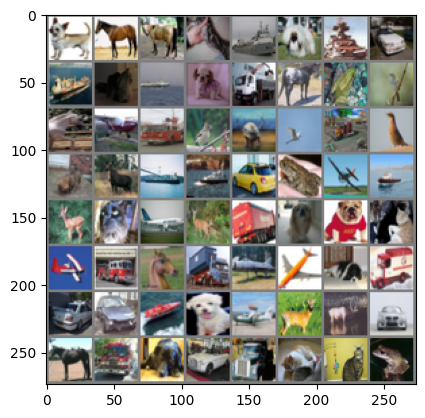

dog   horse horse cat   ship  dog   ship  car   ship  cat   ship  dog   truck horse frog  bird  horse plane truck bird  deer  bird  truck bird  dog   deer  ship  ship  car   frog  plane ship  deer  cat   plane deer  truck dog   dog   cat   plane truck horse truck plane plane dog   truck car   car   ship  dog   plane deer  deer  car   horse truck dog   car   truck cat   cat   frog 


In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Function to display an image
def imshow(img):
    img = img / 2 + 0.5  # Unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Get a batch of training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Display images
imshow(torchvision.utils.make_grid(images))

# Print corresponding labels
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(len(labels))))

In [12]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.SGD(
    net.parameters(),
    lr=0.001,
    momentum=0.9
)

In [14]:

# ---- Week 2 training loop ----

num_epochs = 10

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(num_epochs):

    # ---------------- TRAINING ----------------
    net.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in trainloader:

        # Move data to GPU
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = net(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)

        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # ---------------- VALIDATION ----------------
    net.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for inputs, labels in valloader:

            # Move data to GPU
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = net(inputs)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * inputs.size(0)

            _, predicted = torch.max(outputs, 1)
            val_correct += (predicted == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = 100.0 * val_correct / val_total

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # ---------------- LOGGING ----------------
    gap = train_acc - val_acc

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}% "
        f"| Gap: {gap:+.2f}%"
    )

print("Finished Training")
print("Trains the CNN for 10 epochs using mini-batches and updates its weights through backpropagation and SGD Evaluates the model on the validation set after each epoch, recording loss, accuracy, and the generalization gap")

Epoch [1/10] | Train Loss: 1.4464 | Train Acc: 47.26% | Val Loss: 1.4778 | Val Acc: 45.62% | Gap: +1.64%
Epoch [2/10] | Train Loss: 1.4128 | Train Acc: 48.64% | Val Loss: 1.4316 | Val Acc: 47.84% | Gap: +0.80%
Epoch [3/10] | Train Loss: 1.3774 | Train Acc: 49.95% | Val Loss: 1.3967 | Val Acc: 49.82% | Gap: +0.13%
Epoch [4/10] | Train Loss: 1.3516 | Train Acc: 51.14% | Val Loss: 1.3792 | Val Acc: 50.32% | Gap: +0.82%
Epoch [5/10] | Train Loss: 1.3253 | Train Acc: 52.22% | Val Loss: 1.3480 | Val Acc: 51.46% | Gap: +0.76%
Epoch [6/10] | Train Loss: 1.2957 | Train Acc: 53.20% | Val Loss: 1.3383 | Val Acc: 52.14% | Gap: +1.06%
Epoch [7/10] | Train Loss: 1.2694 | Train Acc: 54.27% | Val Loss: 1.3042 | Val Acc: 53.84% | Gap: +0.43%
Epoch [8/10] | Train Loss: 1.2469 | Train Acc: 55.33% | Val Loss: 1.2868 | Val Acc: 54.50% | Gap: +0.83%
Epoch [9/10] | Train Loss: 1.2232 | Train Acc: 56.32% | Val Loss: 1.2474 | Val Acc: 55.14% | Gap: +1.18%
Epoch [10/10] | Train Loss: 1.1992 | Train Acc: 57.16% 

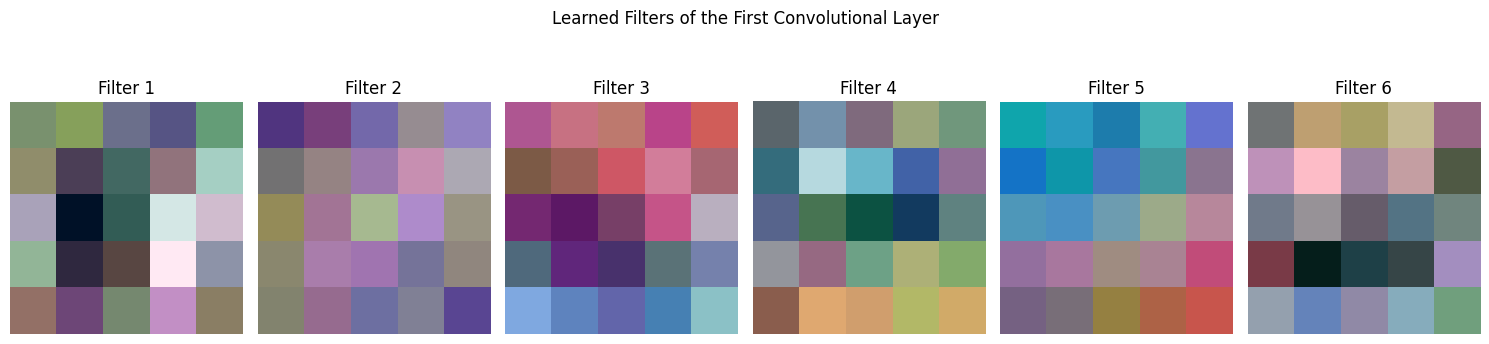

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# Get learned weights from the first convolutional layer
filters = net.conv1.weight.detach().clone()

# Move filters to CPU
filters = filters.cpu()

# Normalize filters for visualization
filters = (filters - filters.min()) / (filters.max() - filters.min())

# Create a figure
fig, axes = plt.subplots(1, 6, figsize=(15, 4))

for i in range(6):
    filter_img = filters[i]

    # Convert (C, H, W) to (H, W, C)
    filter_img = np.transpose(filter_img.numpy(), (1, 2, 0))

    axes[i].imshow(filter_img)
    axes[i].set_title(f'Filter {i+1}')
    axes[i].axis('off')

plt.suptitle('Learned Filters of the First Convolutional Layer')
plt.tight_layout()
plt.show()

Visualizes the learned filters of the first convolutional layer to show the patterns and features detected by the CNN.
Displays the six filters as images after normalization for better visualization.

In [16]:
PATH = DATA_DIR + "/cifar_net.pt"

torch.save(net.state_dict(), PATH)

print("Model saved successfully!")

Model saved successfully!


Saves the trained CNN model's learned parameters (weights and biases) using state_dict().
Stores the model in Google Drive so it can be loaded again after a runtime disconnection.

In [17]:
# Load the saved model
net = Net().to(device)

net.load_state_dict(
    torch.load(PATH, map_location=device, weights_only=True)
)

net.eval()

print("Model loaded successfully!")

Model loaded successfully!


Loads the previously saved CNN weights into the model without retraining it.
Sets the model to evaluation mode to prepare it for testing and inference.

In [18]:
correct = 0
total = 0
net.eval()
# No gradient calculation is needed during testing
with torch.no_grad():
    for images, labels in testloader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Get model predictions
        outputs = net(images)

        # Select the class with the highest score
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct / total:.2f}%')

Accuracy of the network on the 10000 test images: 56.66%


Evaluates the trained CNN on the 10,000 unseen CIFAR-10 test images without updating model weights.
Calculates and displays the overall test accuracy based on the model's predictions

In [19]:
# Prepare counters for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}
net.eval()
# No gradients needed during evaluation
with torch.no_grad():
    for images, labels in testloader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        outputs = net(images)
        _, predictions = torch.max(outputs, 1)

        # Collect correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label.item()]] += 1

            total_pred[classes[label.item()]] += 1

# Print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 49.1 %
Accuracy for class: car   is 74.5 %
Accuracy for class: bird  is 37.5 %
Accuracy for class: cat   is 34.1 %
Accuracy for class: deer  is 47.4 %
Accuracy for class: dog   is 47.7 %
Accuracy for class: frog  is 74.4 %
Accuracy for class: horse is 60.2 %
Accuracy for class: ship  is 78.4 %
Accuracy for class: truck is 63.3 %


Evaluates the CNN's classification performance separately for each of the 10 CIFAR-10 classes.
Calculates and displays the percentage of correctly classified images for every class.

##CNN with Batch Normalization and Residual Connections.

In [20]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class CNNWithBNResidual(nn.Module):

    def __init__(self, use_bn=False, use_residual=False):
        super().__init__()

        self.use_bn = use_bn
        self.use_residual = use_residual

        # Convolutional layers
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.conv3 = nn.Conv2d(16, 32, 3)

        # Batch Normalization layers
        self.bn1 = nn.BatchNorm2d(6)
        self.bn2 = nn.BatchNorm2d(16)
        self.bn3 = nn.BatchNorm2d(32)

        self.pool = nn.MaxPool2d(2, 2)

        # Projection shortcut for residual connection
        self.shortcut = nn.Conv2d(16, 32, kernel_size=3)

        # Fully connected layers
        self.fc1 = nn.Linear(32 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):

        # First convolution
        x = self.conv1(x)

        if self.use_bn:
            x = self.bn1(x)

        x = self.pool(F.relu(x))

        # Second convolution
        x = self.conv2(x)

        if self.use_bn:
            x = self.bn2(x)

        x = F.relu(x)

        # Third convolution
        main = self.conv3(x)

        if self.use_bn:
            main = self.bn3(main)

        # Residual connection
        if self.use_residual:
            skip = self.shortcut(x)
            x = F.relu(main + skip)
        else:
            x = F.relu(main)

        x = self.pool(x)

        # Fully connected layers
        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [21]:
# 1. Original CNN (no BN, no residual)
model1 = CNNWithBNResidual(False, False).to(device)

# 2. Batch Normalization only
model2 = CNNWithBNResidual(True, False).to(device)

# 3. Residual connections only
model3 = CNNWithBNResidual(False, True).to(device)

# 4. Batch Normalization + Residual connections
model4 = CNNWithBNResidual(True, True).to(device)

Defines a configurable CNN architecture that supports Batch Normalization and Residual Connections.
Allows four model configurations to be trained and compared while keeping the same underlying architecture.

In [24]:

import time
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Use a larger batch size for these experiments
experiment_batch_size = 64

experiment_trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=experiment_batch_size,
    shuffle=True,
    num_workers=0
)

experiment_valloader = torch.utils.data.DataLoader(
    valset,
    batch_size=experiment_batch_size,
    shuffle=False,
    num_workers=0
)

experiment_testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=experiment_batch_size,
    shuffle=False,
    num_workers=0
)


def train_model(model, epochs=5):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=0.001,
        momentum=0.9
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        # ---------------- TRAINING ----------------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in experiment_trainloader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

            _, predicted = torch.max(outputs, 1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100 * correct / total

        # ---------------- VALIDATION ----------------
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for inputs, labels in experiment_valloader:

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)

                _, predicted = torch.max(outputs, 1)

                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss / val_total
        val_acc = 100 * val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Acc: {train_acc:.2f}% "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Acc: {val_acc:.2f}%"
        )

    training_time = time.time() - start_time

    # ---------------- TEST ACCURACY ----------------
    model.eval()

    test_correct = 0
    test_total = 0

    with torch.no_grad():

        for inputs, labels in experiment_testloader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            test_correct += (predicted == labels).sum().item()
            test_total += labels.size(0)

    test_acc = 100 * test_correct / test_total

    print(f"Training time: {training_time:.2f} seconds")
    print(f"Test accuracy: {test_acc:.2f}%")

    return model, history, training_time, test_acc


In [25]:

# Four configurations
experiments = {
    "No BN / No Residual": {
        "use_bn": False,
        "use_residual": False
    },

    "BN / No Residual": {
        "use_bn": True,
        "use_residual": False
    },

    "No BN / Residual": {
        "use_bn": False,
        "use_residual": True
    },

    "BN / Residual": {
        "use_bn": True,
        "use_residual": True
    }
}

results = {}

seed = 42
epochs = 5

for name, config in experiments.items():

    print("\n" + "=" * 50)
    print("Experiment:", name)
    print("=" * 50)

    # Reset random seed for fair comparison
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Create a new model
    model = CNNWithBNResidual(
        use_bn=config["use_bn"],
        use_residual=config["use_residual"]
    )

    # Train the model
    trained_model, history, training_time, test_acc = train_model(
        model,
        epochs=epochs
    )

    results[name] = {
        "history": history,
        "model": trained_model,
        "time": training_time,
        "test_acc": test_acc
    }

print("\nAll experiments completed!")



Experiment: No BN / No Residual
Epoch [1/5] | Train Loss: 2.3023 | Train Acc: 9.26% | Val Loss: 2.3002 | Val Acc: 12.04%
Epoch [2/5] | Train Loss: 2.2924 | Train Acc: 16.21% | Val Loss: 2.2690 | Val Acc: 17.72%
Epoch [3/5] | Train Loss: 2.1243 | Train Acc: 22.78% | Val Loss: 1.9882 | Val Acc: 28.22%
Epoch [4/5] | Train Loss: 1.9189 | Train Acc: 30.67% | Val Loss: 1.8604 | Val Acc: 32.80%
Epoch [5/5] | Train Loss: 1.7875 | Train Acc: 34.92% | Val Loss: 1.7254 | Val Acc: 36.88%
Training time: 88.81 seconds
Test accuracy: 37.37%

Experiment: BN / No Residual
Epoch [1/5] | Train Loss: 1.9450 | Train Acc: 29.25% | Val Loss: 1.7055 | Val Acc: 37.58%
Epoch [2/5] | Train Loss: 1.5137 | Train Acc: 43.57% | Val Loss: 1.4213 | Val Acc: 48.32%
Epoch [3/5] | Train Loss: 1.3633 | Train Acc: 50.02% | Val Loss: 1.3170 | Val Acc: 53.16%
Epoch [4/5] | Train Loss: 1.2637 | Train Acc: 54.07% | Val Loss: 1.2204 | Val Acc: 56.38%
Epoch [5/5] | Train Loss: 1.1972 | Train Acc: 56.98% | Val Loss: 1.1730 | Val

In [26]:

import pandas as pd

comparison = []

for name, result in results.items():

    history = result["history"]

    comparison.append({
        "Model": name,
        "Final Train Accuracy (%)": round(history["train_acc"][-1], 2),
        "Final Validation Accuracy (%)": round(history["val_acc"][-1], 2),
        "Test Accuracy (%)": round(result["test_acc"], 2),
        "Generalization Gap (%)": round(
            history["train_acc"][-1] - history["val_acc"][-1], 2
        ),
        "Training Time (seconds)": round(result["time"], 2)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df


,Model,Final Train Accuracy (%),Final Validation Accuracy (%),Test Accuracy (%),Generalization Gap (%),Training Time (seconds)
0,No BN / No Residual,34.92,36.88,37.37,-1.96,88.81
1,BN / No Residual,56.98,58.28,58.27,-1.30,89.89
2,No BN / Residual,38.84,39.34,40.89,-0.50,89.32
3,BN / Residual,56.79,56.16,57.07,0.63,90.69


##Create the three augmentation pipelines

In [29]:

from torchvision.transforms import v2
import torch

# CIFAR-10 normalization used in your original notebook
mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)

# 1. NO AUGMENTATION
no_augmentation = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])


# 2. BASIC AUGMENTATION
basic_augmentation = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),

    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomCrop(32, padding=4),

    v2.Normalize(mean, std)
])


# 3. AGGRESSIVE AUGMENTATION
aggressive_augmentation = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),

    v2.RandomResizedCrop(
        size=(32, 32),
        scale=(0.6, 1.0)
    ),

    v2.RandomHorizontalFlip(p=0.5),

    v2.ColorJitter(
        brightness=0.4,
        contrast=0.4,
        saturation=0.4,
        hue=0.1
    ),

    v2.RandomRotation(degrees=20),

    v2.Normalize(mean, std),

    v2.RandomErasing(
        p=0.5,
        scale=(0.02, 0.2)
    )
])

print("All augmentation pipelines created!")


All augmentation pipelines created!


Prepare datasets

In [30]:

from torch.utils.data import DataLoader, Subset
import torchvision

# Create separate datasets with different transformations

train_dataset_no_aug = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=no_augmentation
)

train_dataset_basic = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=basic_augmentation
)

train_dataset_aggressive = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=aggressive_augmentation
)

# Clean dataset for measuring training accuracy
train_dataset_clean = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=no_augmentation
)

# Use EXACTLY the original train/validation indices
train_indices = trainset.indices
val_indices = valset.indices

# Training subsets
train_no_aug = Subset(train_dataset_no_aug, train_indices)
train_basic = Subset(train_dataset_basic, train_indices)
train_aggressive = Subset(train_dataset_aggressive, train_indices)

# Clean training subset for evaluation
train_clean = Subset(train_dataset_clean, train_indices)

# Validation subset: always clean
validation_dataset = Subset(train_dataset_clean, val_indices)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))


Training samples: 45000
Validation samples: 5000


Create DataLoaders

In [31]:
batch_size = 128
# No augmentation
loader_no_aug = DataLoader(
    train_no_aug,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)
# Basic augmentation
loader_basic = DataLoader(
    train_basic,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

# Aggressive augmentation
loader_aggressive = DataLoader(
    train_aggressive,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)
# Clean training and validation loaders
train_clean_loader = DataLoader(
    train_clean,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)
print("All DataLoaders are ready!")

All DataLoaders are ready!


Create the training and evaluation function

In [32]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

In [33]:
import time
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
def evaluate_model(model, loader, criterion):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy


def train_augmentation_experiment(
    train_dataset,
    experiment_name,
    epochs=10,
    seed=42
):

    # Reset seed for fair comparison
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Recreate loader with the same shuffle seed
    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=128,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    # Create a fresh copy of the SAME architecture
    model = Net().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=0.001,
        momentum=0.9
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "fit_loss": []
    }

    start_time = time.time()

    for epoch in range(epochs):

        # ---------------- TRAINING ----------------

        model.train()

        running_loss = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total += images.size(0)

        fit_loss = running_loss / total

        # -------- CLEAN TRAINING EVALUATION --------

        train_loss, train_acc = evaluate_model(
            model,
            train_clean_loader,
            criterion
        )

        # ---------------- VALIDATION ----------------

        val_loss, val_acc = evaluate_model(
            model,
            validation_loader,
            criterion
        )

        # Generalization gap
        gap = train_acc - val_acc

        history["fit_loss"].append(fit_loss)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"{experiment_name} | "
            f"Epoch [{epoch+1}/{epochs}] "
            f"| Fit Loss: {fit_loss:.4f} "
            f"| Train Acc: {train_acc:.2f}% "
            f"| Val Acc: {val_acc:.2f}% "
            f"| Gap: {gap:.2f}%"
        )

    training_time = time.time() - start_time

    print(f"\n{experiment_name} completed!")
    print(f"Training time: {training_time:.2f} seconds")

    return model, history, training_time


Run the three experiments

In [34]:
# Use the same number of epochs for all experiments
epochs = 10
seed = 42

augmentation_experiments = {
    "No Augmentation": train_no_aug,
    "Basic Augmentation": train_basic,
    "Aggressive Augmentation": train_aggressive
}

augmentation_results = {}

for name, dataset in augmentation_experiments.items():

    print("\n" + "=" * 60)
    print("Starting:", name)
    print("=" * 60)

    model, history, training_time = train_augmentation_experiment(
        train_dataset=dataset,
        experiment_name=name,
        epochs=epochs,
        seed=seed
    )

    augmentation_results[name] = {
        "model": model,
        "history": history,
        "time": training_time
    }
print("\nAll augmentation experiments completed!")


Starting: No Augmentation
No Augmentation | Epoch [1/10] | Fit Loss: 2.3033 | Train Acc: 9.94% | Val Acc: 10.54% | Gap: -0.60%
No Augmentation | Epoch [2/10] | Fit Loss: 2.3014 | Train Acc: 14.74% | Val Acc: 14.28% | Gap: 0.46%
No Augmentation | Epoch [3/10] | Fit Loss: 2.2987 | Train Acc: 14.70% | Val Acc: 13.96% | Gap: 0.74%
No Augmentation | Epoch [4/10] | Fit Loss: 2.2896 | Train Acc: 15.24% | Val Acc: 14.42% | Gap: 0.82%
No Augmentation | Epoch [5/10] | Fit Loss: 2.2209 | Train Acc: 21.92% | Val Acc: 21.12% | Gap: 0.80%
No Augmentation | Epoch [6/10] | Fit Loss: 2.0961 | Train Acc: 27.46% | Val Acc: 27.34% | Gap: 0.12%
No Augmentation | Epoch [7/10] | Fit Loss: 1.9671 | Train Acc: 30.68% | Val Acc: 30.42% | Gap: 0.26%
No Augmentation | Epoch [8/10] | Fit Loss: 1.8980 | Train Acc: 32.95% | Val Acc: 32.14% | Gap: 0.81%
No Augmentation | Epoch [9/10] | Fit Loss: 1.8259 | Train Acc: 35.75% | Val Acc: 34.90% | Gap: 0.85%
No Augmentation | Epoch [10/10] | Fit Loss: 1.7436 | Train Acc: 

Plot the training curves

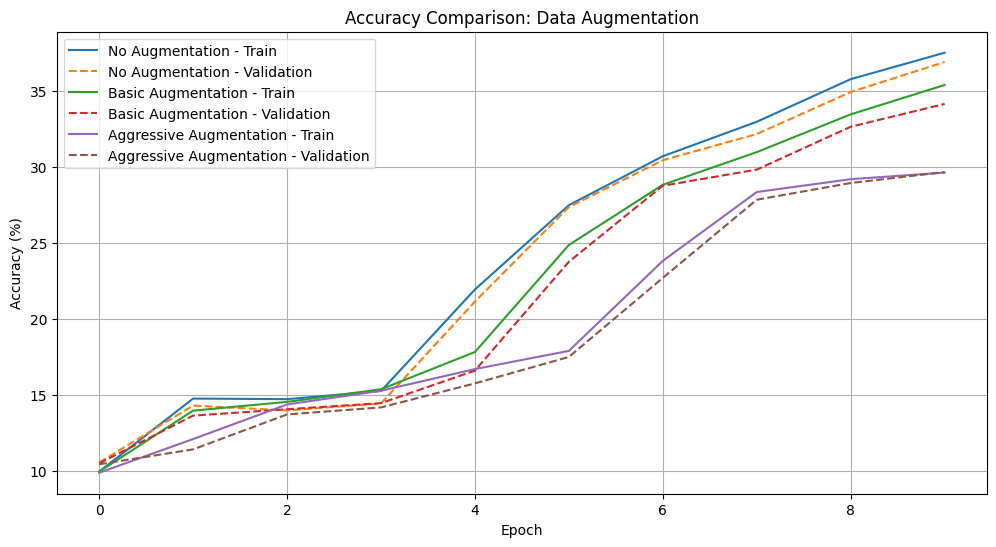

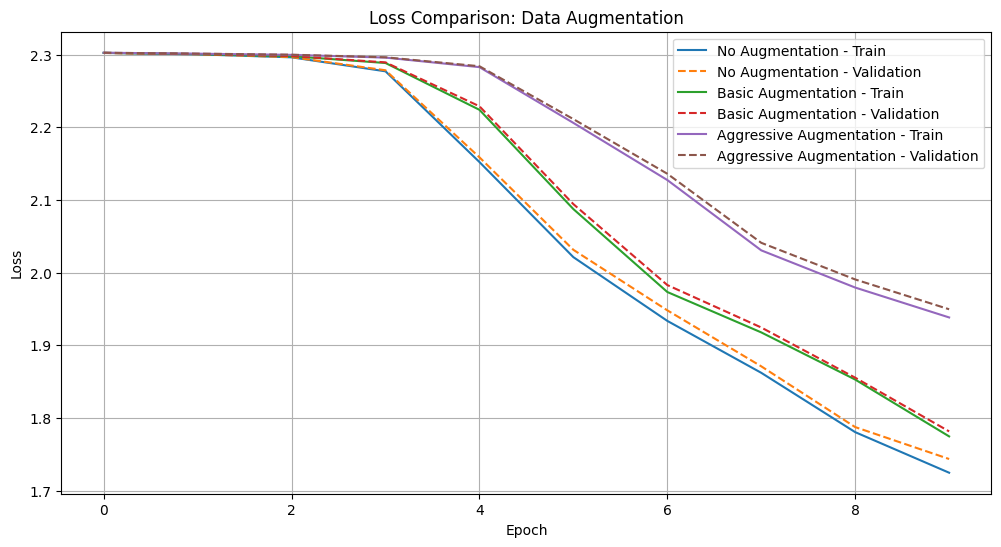

In [35]:
import matplotlib.pyplot as plt
# -------- ACCURACY COMPARISON --------
plt.figure(figsize=(12, 6))

for name, result in augmentation_results.items():

    history = result["history"]

    plt.plot(
        history["train_acc"],
        label=f"{name} - Train"
    )

    plt.plot(
        history["val_acc"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.title("Accuracy Comparison: Data Augmentation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()
plt.show()


# -------- LOSS COMPARISON --------

plt.figure(figsize=(12, 6))

for name, result in augmentation_results.items():

    history = result["history"]

    plt.plot(
        history["train_loss"],
        label=f"{name} - Train"
    )

    plt.plot(
        history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

plt.title("Loss Comparison: Data Augmentation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

Create the comparison table

In [36]:

import pandas as pd

augmentation_comparison = []

for name, result in augmentation_results.items():

    history = result["history"]

    train_acc = history["train_acc"][-1]
    val_acc = history["val_acc"][-1]

    augmentation_comparison.append({

        "Experiment": name,

        "Train Accuracy (%)": round(train_acc, 2),

        "Validation Accuracy (%)": round(val_acc, 2),

        "Generalization Gap (%)": round(
            train_acc - val_acc, 2
        ),

        "Training Time (seconds)": round(
            result["time"], 2
        )
    })

augmentation_df = pd.DataFrame(augmentation_comparison)

augmentation_df

,Experiment,Train Accuracy (%),Validation Accuracy (%),Generalization Gap (%),Training Time (seconds)
0,No Augmentation,37.49,36.88,0.61,295.97
1,Basic Augmentation,35.37,34.12,1.25,398.20
2,Aggressive Augmentation,29.60,29.64,-0.04,1132.34


##Transfer Learning: ResNet-18 vs CNN from Scratch



In [38]:
#Prepare CIFAR-10 for ResNet-18

from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader, Subset

# ImageNet normalization
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)

# Training transformations
resnet_train_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.RandomHorizontalFlip(p=0.5),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(imagenet_mean, imagenet_std)
])

# Validation and testing transformations
resnet_test_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(imagenet_mean, imagenet_std)
])

# Create datasets
resnet_train_data = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=resnet_train_transform
)

resnet_clean_data = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=resnet_test_transform
)

resnet_test_data = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=resnet_test_transform
)

# Preserve the original train/validation split
resnet_train_subset = Subset(
    resnet_train_data,
    trainset.indices
)

resnet_val_subset = Subset(
    resnet_clean_data,
    valset.indices
)

# DataLoaders
resnet_batch_size = 64

resnet_trainloader = DataLoader(
    resnet_train_subset,
    batch_size=resnet_batch_size,
    shuffle=True,
    num_workers=0
)

resnet_valloader = DataLoader(
    resnet_val_subset,
    batch_size=resnet_batch_size,
    shuffle=False,
    num_workers=0
)

resnet_testloader = DataLoader(
    resnet_test_data,
    batch_size=resnet_batch_size,
    shuffle=False,
    num_workers=0
)

print("ResNet datasets are ready!")
print("Training:", len(resnet_train_subset))
print("Validation:", len(resnet_val_subset))
print("Testing:", len(resnet_test_data))


ResNet datasets are ready!
Training: 45000
Validation: 5000
Testing: 10000


Import pretrained ResNet-18

In [39]:
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

# Load pretrained ResNet-18
weights = ResNet18_Weights.DEFAULT

resnet_model = resnet18(weights=weights)

# Check original classifier
print("Original output features:", resnet_model.fc.out_features)

# Replace final classification layer
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    10
)

resnet_model = resnet_model.to(device)

print("ResNet-18 is ready for CIFAR-10!")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 149MB/s]

Original output features: 1000
ResNet-18 is ready for CIFAR-10!


A. Fine-tuning

In [40]:
for param in model.parameters():
    param.requires_grad = True

create resnet model

In [41]:
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

# Load pretrained ResNet-18
model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Replace the final classifier to output 10 CIFAR-10 classes
model.fc = nn.Linear(model.fc.in_features, 10)

model = model.to(device)

B. Fixed feature extractor
We freeze all layers except the final classifier.

In [42]:
# Freeze all layers
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the final classifier
for param in model.fc.parameters():
    param.requires_grad = True

C. Training from scratch
We don't load ImageNet weights.

In [43]:
model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 10)

Step 7 — Create one reusable training function
Instead of writing three separate training loops, we'll create one function that supports all three strategies.

It will calculate:
- Training loss.
- Validation loss.
- Validation accuracy.
- Training time.
- Final test accuracy.
Add a new code cell.

In [44]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
def evaluate_resnet(model, loader, criterion):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = 100 * correct / total

    return avg_loss, accuracy


def train_resnet(strategy, epochs=5, seed=42):

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # ---------------- CREATE MODEL ----------------

    if strategy == "scratch":

        # Randomly initialized ResNet-18
        model = resnet18(weights=None)

        model.fc = nn.Linear(
            model.fc.in_features, 10
        )

    else:

        # Load ImageNet pretrained ResNet-18
        model = resnet18(weights=ResNet18_Weights.DEFAULT)

        model.fc = nn.Linear(
            model.fc.in_features, 10
        )

        if strategy == "feature_extractor":

            # Freeze all parameters
            for param in model.parameters():
                param.requires_grad = False

            # Unfreeze the classifier
            for param in model.fc.parameters():
                param.requires_grad = True

        elif strategy == "fine_tuning":

            # Train all parameters
            for param in model.parameters():
                param.requires_grad = True

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    # ---------------- OPTIMIZER ----------------

    if strategy == "fine_tuning":

        # Smaller learning rate for pretrained layers
        optimizer = optim.AdamW([
            {
                "params": [
                    p for n, p in model.named_parameters()
                    if not n.startswith("fc.")
                ],
                "lr": 0.0001
            },
            {
                "params": model.fc.parameters(),
                "lr": 0.001
            }
        ], weight_decay=0.0001)

    elif strategy == "feature_extractor":

        optimizer = optim.AdamW(
            model.fc.parameters(),
            lr=0.001,
            weight_decay=0.0001
        )

    else:

        optimizer = optim.AdamW(
            model.parameters(),
            lr=0.001,
            weight_decay=0.0001
        )

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": []
    }

    start_time = time.time()

    # ---------------- TRAINING ----------------

    for epoch in range(epochs):

        model.train()

        # Keep frozen backbone BatchNorm statistics unchanged
        if strategy == "feature_extractor":
            model.eval()
            model.fc.train()

        running_loss = 0
        total = 0

        for images, labels in resnet_trainloader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total += labels.size(0)

        train_loss = running_loss / total

        # ---------------- VALIDATION ----------------

        val_loss, val_acc = evaluate_resnet(
            model,
            resnet_valloader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"{strategy} | Epoch [{epoch+1}/{epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Accuracy: {val_acc:.2f}%"
        )

    training_time = time.time() - start_time

    # ---------------- TESTING ----------------

    test_loss, test_acc = evaluate_resnet(
        model,
        resnet_testloader,
        criterion
    )

    print("\nTraining completed!")
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Test accuracy: {test_acc:.2f}%")

    return model, history, training_time, test_acc


Run the three experiments

In [45]:
resnet_experiments = {
    "fine_tuning": "Fine-Tuning",
    "feature_extractor": "Fixed Feature Extractor",
    "scratch": "Training From Scratch"
}

resnet_results = {}

epochs = 5

for strategy, name in resnet_experiments.items():

    print("\n" + "=" * 60)
    print("Starting:", name)
    print("=" * 60)

    model, history, training_time, test_acc = train_resnet(
        strategy=strategy,
        epochs=epochs,
        seed=42
    )

    resnet_results[strategy] = {
        "model": model,
        "history": history,
        "time": training_time,
        "test_acc": test_acc
    }

print("\nAll ResNet experiments completed!")



Starting: Fine-Tuning
fine_tuning | Epoch [1/5] | Train Loss: 0.3335 | Val Loss: 0.1849 | Val Accuracy: 93.78%
fine_tuning | Epoch [2/5] | Train Loss: 0.1473 | Val Loss: 0.1874 | Val Accuracy: 93.60%
fine_tuning | Epoch [3/5] | Train Loss: 0.0960 | Val Loss: 0.1699 | Val Accuracy: 94.44%
fine_tuning | Epoch [4/5] | Train Loss: 0.0692 | Val Loss: 0.1981 | Val Accuracy: 93.82%
fine_tuning | Epoch [5/5] | Train Loss: 0.0591 | Val Loss: 0.1757 | Val Accuracy: 94.46%

Training completed!
Training time: 1231.09 seconds
Test accuracy: 94.38%

Starting: Fixed Feature Extractor
feature_extractor | Epoch [1/5] | Train Loss: 0.5856 | Val Loss: 0.4110 | Val Accuracy: 85.78%
feature_extractor | Epoch [2/5] | Train Loss: 0.3914 | Val Loss: 0.3745 | Val Accuracy: 87.12%
feature_extractor | Epoch [3/5] | Train Loss: 0.3621 | Val Loss: 0.3666 | Val Accuracy: 87.14%
feature_extractor | Epoch [4/5] | Train Loss: 0.3482 | Val Loss: 0.3457 | Val Accuracy: 87.94%
feature_extractor | Epoch [5/5] | Train Los

Compare the training curves

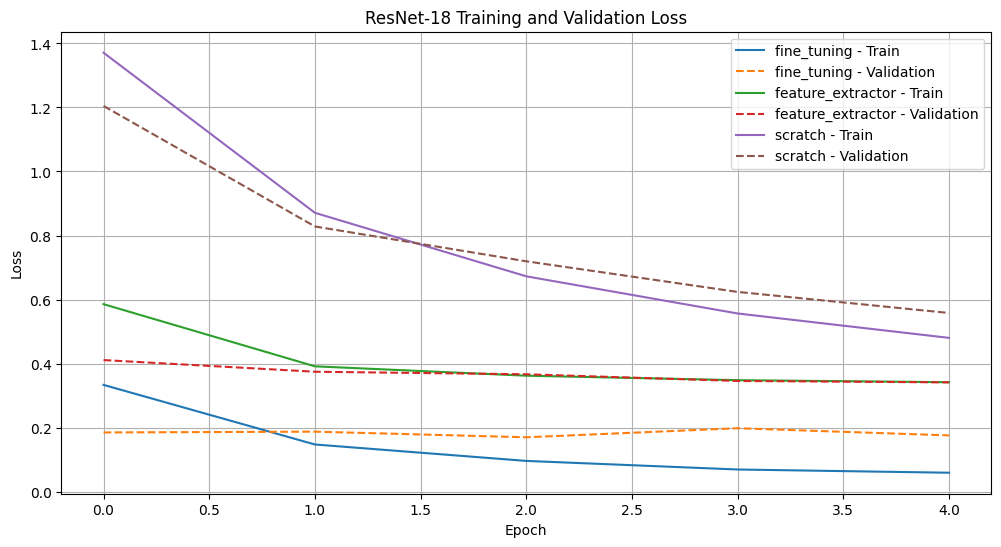

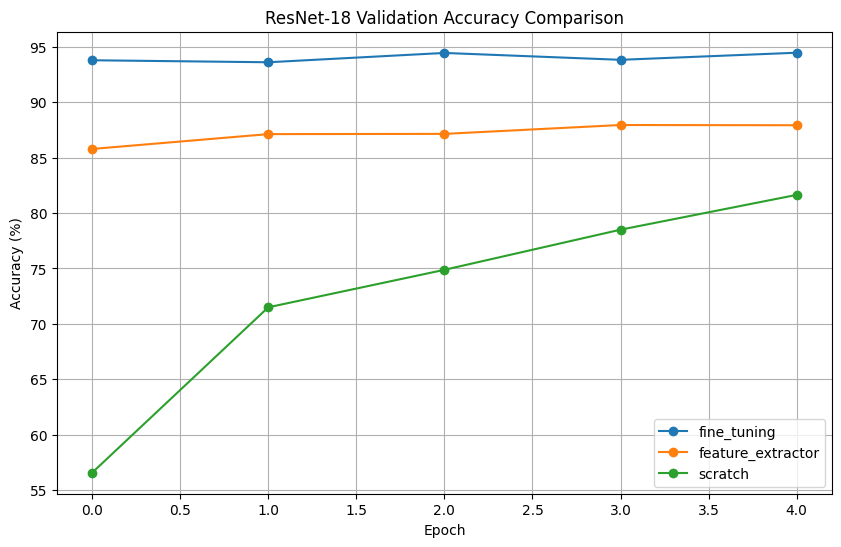

In [46]:

import matplotlib.pyplot as plt

# -------- LOSS COMPARISON --------

plt.figure(figsize=(12, 6))

for strategy, result in resnet_results.items():

    history = result["history"]

    plt.plot(
        history["train_loss"],
        label=f"{strategy} - Train"
    )

    plt.plot(
        history["val_loss"],
        linestyle="--",
        label=f"{strategy} - Validation"
    )

plt.title("ResNet-18 Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


# -------- VALIDATION ACCURACY --------

plt.figure(figsize=(10, 6))

for strategy, result in resnet_results.items():

    history = result["history"]

    plt.plot(
        history["val_acc"],
        marker="o",
        label=strategy
    )

plt.title("ResNet-18 Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()
plt.show()

Create the final comparison table

In [47]:

import pandas as pd

resnet_comparison = []

for strategy, result in resnet_results.items():

    resnet_comparison.append({

        "Strategy": resnet_experiments[strategy],

        "Final Validation Accuracy (%)": round(
            result["history"]["val_acc"][-1], 2
        ),

        "Test Accuracy (%)": round(
            result["test_acc"], 2
        ),

        "Training Time (seconds)": round(
            result["time"], 2
        ),

        "Trainable Parameters": sum(
            p.numel()
            for p in result["model"].parameters()
            if p.requires_grad
        )
    })

resnet_comparison_df = pd.DataFrame(resnet_comparison)

resnet_comparison_df

,Strategy,Final Validation Accuracy (%),Test Accuracy (%),Training Time (seconds),Trainable Parameters
0,Fine-Tuning,94.46,94.38,1231.09,11181642
1,Fixed Feature Extractor,87.92,86.87,572.13,5130
2,Training From Scratch,81.64,81.20,1114.53,11181642


Investigate how much data each model needs

In [48]:

import torch
from torch.utils.data import Subset, DataLoader

# Different training dataset sizes
data_fractions = [0.10, 0.25, 1.0]

# Use fewer epochs for this additional experiment
data_experiment_epochs = 3

data_efficiency_results = []

# Generate one reproducible ordering of training indices
generator = torch.Generator().manual_seed(42)

permutation = torch.randperm(
    len(trainset),
    generator=generator
).tolist()

original_resnet_trainloader = resnet_trainloader

for fraction in data_fractions:

    number_of_samples = int(len(trainset) * fraction)

    selected_indices = [
        trainset.indices[i]
        for i in permutation[:number_of_samples]
    ]

    # Create a smaller training subset
    small_train_dataset = Subset(
        resnet_train_data,
        selected_indices
    )

    resnet_trainloader = DataLoader(
        small_train_dataset,
        batch_size=64,
        shuffle=True,
        num_workers=0,
        generator=torch.Generator().manual_seed(42)
    )

    print("\n" + "=" * 60)
    print(f"Training with {fraction*100:.0f}% of the data")
    print(f"Number of images: {number_of_samples}")
    print("=" * 60)

    # Compare fine-tuning and scratch
    for strategy in ["fine_tuning", "scratch"]:

        model, history, training_time, test_acc = train_resnet(
            strategy=strategy,
            epochs=data_experiment_epochs,
            seed=42
        )

        data_efficiency_results.append({

            "Strategy": strategy,

            "Training Data (%)": fraction * 100,

            "Number of Images": number_of_samples,

            "Validation Accuracy (%)": round(
                history["val_acc"][-1], 2
            ),

            "Test Accuracy (%)": round(test_acc, 2),

            "Training Time (seconds)": round(
                training_time, 2
            )
        })

# Restore the original full training loader
resnet_trainloader = original_resnet_trainloader

data_efficiency_df = pd.DataFrame(data_efficiency_results)

data_efficiency_df


Training with 10% of the data
Number of images: 4500
fine_tuning | Epoch [1/3] | Train Loss: 0.8502 | Val Loss: 0.4293 | Val Accuracy: 84.76%
fine_tuning | Epoch [2/3] | Train Loss: 0.2521 | Val Loss: 0.3957 | Val Accuracy: 86.40%
fine_tuning | Epoch [3/3] | Train Loss: 0.1220 | Val Loss: 0.3196 | Val Accuracy: 88.92%

Training completed!
Training time: 97.31 seconds
Test accuracy: 89.19%
scratch | Epoch [1/3] | Train Loss: 1.9529 | Val Loss: 2.0560 | Val Accuracy: 29.32%
scratch | Epoch [2/3] | Train Loss: 1.6883 | Val Loss: 1.7290 | Val Accuracy: 38.56%
scratch | Epoch [3/3] | Train Loss: 1.5329 | Val Loss: 1.5624 | Val Accuracy: 44.98%

Training completed!
Training time: 97.40 seconds
Test accuracy: 44.22%

Training with 25% of the data
Number of images: 11250
fine_tuning | Epoch [1/3] | Train Loss: 0.5648 | Val Loss: 0.3120 | Val Accuracy: 88.70%
fine_tuning | Epoch [2/3] | Train Loss: 0.1856 | Val Loss: 0.2900 | Val Accuracy: 90.68%
fine_tuning | Epoch [3/3] | Train Loss: 0.0938 

,Strategy,Training Data (%),Number of Images,Validation Accuracy (%),Test Accuracy (%),Training Time (seconds)
0,fine_tuning,10.0,4500,88.92,89.19,97.31
1,scratch,10.0,4500,44.98,44.22,97.40
2,fine_tuning,25.0,11250,91.44,91.03,194.09
3,scratch,25.0,11250,54.54,55.20,194.27
4,fine_tuning,100.0,45000,94.26,93.80,670.95
5,scratch,100.0,45000,70.98,70.88,666.66


Plot the data-efficiency results

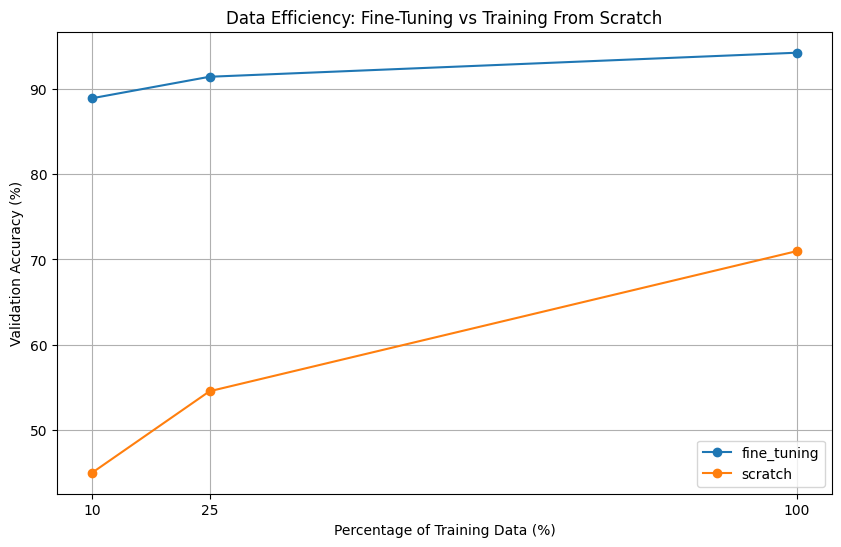

In [49]:

plt.figure(figsize=(10, 6))

for strategy in ["fine_tuning", "scratch"]:

    subset = data_efficiency_df[
        data_efficiency_df["Strategy"] == strategy
    ]

    plt.plot(
        subset["Training Data (%)"],
        subset["Validation Accuracy (%)"],
        marker="o",
        label=strategy
    )

plt.title("Data Efficiency: Fine-Tuning vs Training From Scratch")
plt.xlabel("Percentage of Training Data (%)")
plt.ylabel("Validation Accuracy (%)")
plt.xticks([10, 25, 100])
plt.legend()
plt.grid()
plt.show()

##Investigating Why Fine-Tuning Can Fail

In [51]:
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader, Subset

# Correct ImageNet normalization
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)

# Incorrect normalization for pretrained ResNet
wrong_mean = (0.5, 0.5, 0.5)
wrong_std = (0.5, 0.5, 0.5)


# Correct preprocessing
correct_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(imagenet_mean, imagenet_std)
])


# Incorrect preprocessing
wrong_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(wrong_mean, wrong_std)
])


# Create datasets
correct_train_data = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=correct_transform
)

wrong_train_data = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=wrong_transform
)


# Select 10% of the original training data
torch.manual_seed(42)

num_samples = int(len(trainset) * 0.10)

selected_positions = torch.randperm(
    len(trainset)
)[:num_samples].tolist()

selected_indices = [
    trainset.indices[i] for i in selected_positions
]

# Use the same selected images for every experiment
correct_train_subset = Subset(
    correct_train_data,
    selected_indices
)

wrong_train_subset = Subset(
    wrong_train_data,
    selected_indices
)

# Validation datasets use the same original validation indices
correct_val_subset = Subset(
    correct_train_data,
    valset.indices
)

wrong_val_subset = Subset(
    wrong_train_data,
    valset.indices
)

print("Training images:", num_samples)
print("Validation images:", len(valset))


Training images: 4500
Validation images: 5000


In [52]:
batch_size = 64
def create_failure_loaders(wrong_normalization=False):

    if wrong_normalization:

        train_data = wrong_train_subset
        val_data = wrong_val_subset

    else:

        train_data = correct_train_subset
        val_data = correct_val_subset

    generator = torch.Generator().manual_seed(42)

    train_loader = DataLoader(
        train_data,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    val_loader = DataLoader(
        val_data,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader


print("Failure investigation DataLoaders are ready!")

Failure investigation DataLoaders are ready!


Create DataLoaders

In [53]:
batch_size = 64
def create_failure_loaders(wrong_normalization=False):

    if wrong_normalization:

        train_data = wrong_train_subset
        val_data = wrong_val_subset

    else:

        train_data = correct_train_subset
        val_data = correct_val_subset

    generator = torch.Generator().manual_seed(42)

    train_loader = DataLoader(
        train_data,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        generator=generator
    )

    val_loader = DataLoader(
        val_data,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader
print("Failure investigation DataLoaders are ready!")

Failure investigation DataLoaders are ready!


Build the failure investigation training function

In [54]:
import torch.nn as nn
import torch.optim as optim
import time
def evaluate_failure_model(model, loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return (
        total_loss / total,
        100 * correct / total
    )


def investigate_fine_tuning(
    experiment,
    epochs=3,
    seed=42
):

    # Same seed for every experiment
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Select the correct dataset
    wrong_normalization = (
        experiment == "wrong_normalization"
    )

    train_loader, val_loader = create_failure_loaders(
        wrong_normalization
    )

    # Load the SAME pretrained architecture
    model = resnet18(
        weights=ResNet18_Weights.DEFAULT
    )

    # Replace classifier
    model.fc = nn.Linear(
        model.fc.in_features,
        10
    )

    # ---------------- FREEZING EXPERIMENT ----------------

    if experiment == "frozen_backbone":

        # Freeze all layers
        for param in model.parameters():
            param.requires_grad = False

        # Train only final classifier
        for param in model.fc.parameters():
            param.requires_grad = True

    else:

        # Allow all layers to train
        for param in model.parameters():
            param.requires_grad = True

    model = model.to(device)

    # ---------------- LEARNING RATE ----------------

    if experiment == "high_learning_rate":

        # Deliberately high learning rate
        optimizer = optim.AdamW(
            model.parameters(),
            lr=0.01
        )

    elif experiment == "frozen_backbone":

        optimizer = optim.AdamW(
            model.fc.parameters(),
            lr=0.001
        )

    else:

        # Correct differential learning rates
        optimizer = optim.AdamW([
            {
                "params": [
                    p for n, p in model.named_parameters()
                    if not n.startswith("fc.")
                ],
                "lr": 0.0001
            },
            {
                "params": model.fc.parameters(),
                "lr": 0.001
            }
        ], weight_decay=0.0001)

    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc": []
    }

    start_time = time.time()

    # ---------------- TRAINING ----------------

    for epoch in range(epochs):

        model.train()

        # Keep frozen backbone in evaluation mode
        if experiment == "frozen_backbone":
            model.eval()
            model.fc.train()

        running_loss = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total += images.size(0)

        train_loss = running_loss / total

        # ---------------- VALIDATION ----------------

        val_loss, val_acc = evaluate_failure_model(
            model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"{experiment} | Epoch [{epoch+1}/{epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Accuracy: {val_acc:.2f}%"
        )

    training_time = time.time() - start_time

    print(f"\nTraining time: {training_time:.2f} seconds")

    return model, history, training_time


run the experiment

In [55]:

from torchvision.models import ResNet18_Weights

failure_experiments = {
    "correct": "Correct Fine-Tuning",
    "high_learning_rate": "High Learning Rate",
    "frozen_backbone": "Frozen Backbone",
    "wrong_normalization": "Wrong Normalization"
}

failure_results = {}

for experiment, name in failure_experiments.items():

    print("\n" + "=" * 60)
    print("Starting:", name)
    print("=" * 60)

    model, history, training_time = investigate_fine_tuning(
        experiment=experiment,
        epochs=3,
        seed=42
    )

    failure_results[experiment] = {
        "model": model,
        "history": history,
        "time": training_time
    }

print("\nAll failure investigation experiments completed!")



Starting: Correct Fine-Tuning
correct | Epoch [1/3] | Train Loss: 0.8428 | Val Loss: 0.4515 | Val Accuracy: 84.12%
correct | Epoch [2/3] | Train Loss: 0.1831 | Val Loss: 0.3884 | Val Accuracy: 86.42%
correct | Epoch [3/3] | Train Loss: 0.0404 | Val Loss: 0.3417 | Val Accuracy: 88.68%

Training time: 107.69 seconds

Starting: High Learning Rate
high_learning_rate | Epoch [1/3] | Train Loss: 2.6779 | Val Loss: 9.8398 | Val Accuracy: 19.32%
high_learning_rate | Epoch [2/3] | Train Loss: 2.1596 | Val Loss: 2.1491 | Val Accuracy: 19.34%
high_learning_rate | Epoch [3/3] | Train Loss: 2.0175 | Val Loss: 2.0556 | Val Accuracy: 23.84%

Training time: 96.64 seconds

Starting: Frozen Backbone
frozen_backbone | Epoch [1/3] | Train Loss: 1.3396 | Val Loss: 0.8015 | Val Accuracy: 78.12%
frozen_backbone | Epoch [2/3] | Train Loss: 0.6724 | Val Loss: 0.6233 | Val Accuracy: 81.26%
frozen_backbone | Epoch [3/3] | Train Loss: 0.5473 | Val Loss: 0.5554 | Val Accuracy: 81.96%

Training time: 66.43 seconds

Compare the training curves

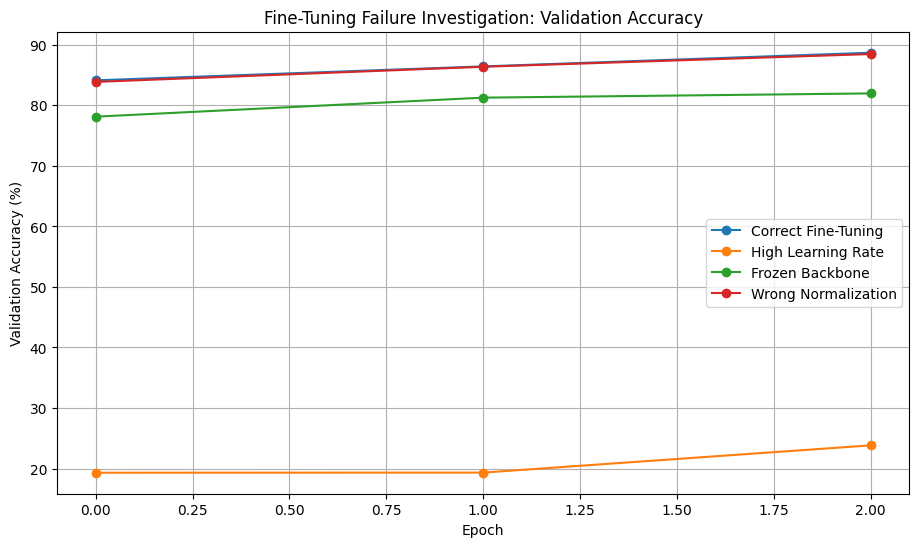

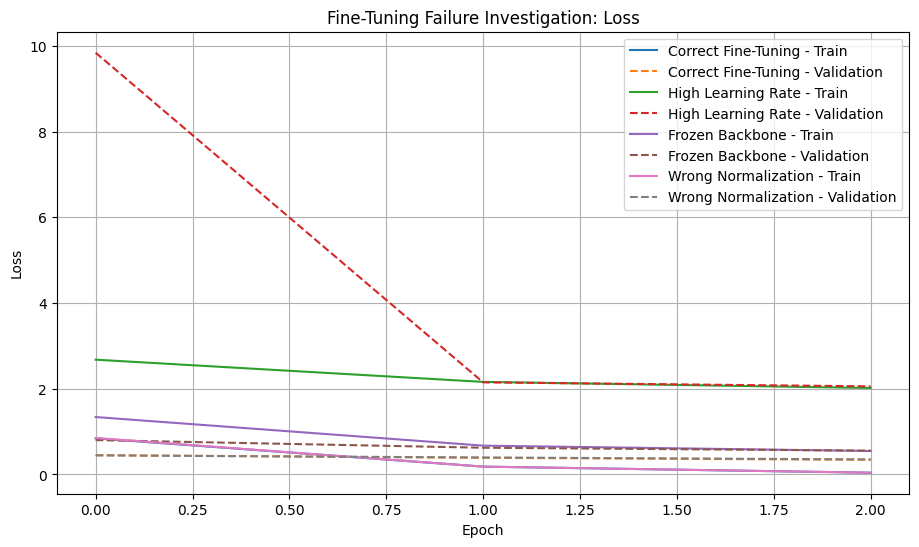

In [56]:

import matplotlib.pyplot as plt

# -------- VALIDATION ACCURACY --------

plt.figure(figsize=(11, 6))

for experiment, result in failure_results.items():

    history = result["history"]

    plt.plot(
        history["val_acc"],
        marker="o",
        label=failure_experiments[experiment]
    )

plt.title("Fine-Tuning Failure Investigation: Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.grid()
plt.show()


# -------- TRAINING AND VALIDATION LOSS --------

plt.figure(figsize=(11, 6))

for experiment, result in failure_results.items():

    history = result["history"]

    plt.plot(
        history["train_loss"],
        label=failure_experiments[experiment] + " - Train"
    )

    plt.plot(
        history["val_loss"],
        linestyle="--",
        label=failure_experiments[experiment] + " - Validation"
    )

plt.title("Fine-Tuning Failure Investigation: Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

Create the comparison table

In [57]:
import pandas as pd
failure_comparison = []
for experiment, result in failure_results.items():

    history = result["history"]

    model = result["model"]

    trainable_params = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    total_params = sum(
        p.numel()
        for p in model.parameters()
    )

    failure_comparison.append({

        "Experiment": failure_experiments[experiment],

        "Final Train Loss": round(
            history["train_loss"][-1], 4
        ),

        "Final Validation Loss": round(
            history["val_loss"][-1], 4
        ),

        "Validation Accuracy (%)": round(
            history["val_acc"][-1], 2
        ),

        "Trainable Parameters": trainable_params,

        "Frozen Parameters": total_params - trainable_params,

        "Training Time (seconds)": round(
            result["time"], 2
        )
    })

failure_df = pd.DataFrame(failure_comparison)

failure_df

,Experiment,Final Train Loss,Final Validation Loss,Validation Accuracy (%),Trainable Parameters,Frozen Parameters,Training Time (seconds)
0,Correct Fine-Tuning,0.0404,0.3417,88.68,11181642,0,107.69
1,High Learning Rate,2.0175,2.0556,23.84,11181642,0,96.64
2,Frozen Backbone,0.5473,0.5554,81.96,5130,11176512,66.43
3,Wrong Normalization,0.0416,0.3514,88.46,11181642,0,98.31


Inspect which layers are frozen

In [58]:

frozen_model = failure_results["frozen_backbone"]["model"]

print("TRAINABLE LAYERS")
print("-" * 40)

for name, param in frozen_model.named_parameters():

    if param.requires_grad:
        print(name)

print("\nFROZEN LAYERS")
print("-" * 40)

for name, param in frozen_model.named_parameters():

    if not param.requires_grad:
        print(name)


TRAINABLE LAYERS
----------------------------------------
fc.weight
fc.bias

FROZEN LAYERS
----------------------------------------
conv1.weight
bn1.weight
bn1.bias
layer1.0.conv1.weight
layer1.0.bn1.weight
layer1.0.bn1.bias
layer1.0.conv2.weight
layer1.0.bn2.weight
layer1.0.bn2.bias
layer1.1.conv1.weight
layer1.1.bn1.weight
layer1.1.bn1.bias
layer1.1.conv2.weight
layer1.1.bn2.weight
layer1.1.bn2.bias
layer2.0.conv1.weight
layer2.0.bn1.weight
layer2.0.bn1.bias
layer2.0.conv2.weight
layer2.0.bn2.weight
layer2.0.bn2.bias
layer2.0.downsample.0.weight
layer2.0.downsample.1.weight
layer2.0.downsample.1.bias
layer2.1.conv1.weight
layer2.1.bn1.weight
layer2.1.bn1.bias
layer2.1.conv2.weight
layer2.1.bn2.weight
layer2.1.bn2.bias
layer3.0.conv1.weight
layer3.0.bn1.weight
layer3.0.bn1.bias
layer3.0.conv2.weight
layer3.0.bn2.weight
layer3.0.bn2.bias
layer3.0.downsample.0.weight
layer3.0.downsample.1.weight
layer3.0.downsample.1.bias
layer3.1.conv1.weight
layer3.1.bn1.weight
layer3.1.bn1.bias
layer

Inspect the learning rates

In [59]:
print("Learning Rate Investigation")
print("-" * 45)
print("Correct fine-tuning:")
print("Backbone learning rate: 0.0001")
print("Classifier learning rate: 0.001")

print("\nHigh learning rate experiment:")
print("All layers learning rate: 0.01")

print("\nFrozen backbone experiment:")
print("Classifier learning rate: 0.001")
print("Backbone learning rate: 0 (frozen)")

print("\nWrong normalization experiment:")
print("Uses the correct fine-tuning learning rates")
print("But uses CIFAR-10 normalization instead of ImageNet")


Learning Rate Investigation
---------------------------------------------
Correct fine-tuning:
Backbone learning rate: 0.0001
Classifier learning rate: 0.001

High learning rate experiment:
All layers learning rate: 0.01

Frozen backbone experiment:
Classifier learning rate: 0.001
Backbone learning rate: 0 (frozen)

Wrong normalization experiment:
Uses the correct fine-tuning learning rates
But uses CIFAR-10 normalization instead of ImageNet
